# 10 — GeoTIFF export and QGIS validation

**Goal:** export analysis-ready rasters (γ⁰ in dB, HH, HV and ratio) and **prove** they are
correctly georeferenced before anyone opens them in QGIS: CRS, pixel size, origin, values,
and overlay with an independent vector layer.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "10"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
session = P.load_session(kit["session_file"], required=("granule", "frequency", "aoi_bounds"))
src_ctx = lambda: P.open_local_or_remote(session["gcov_local"], session["gcov_url"])
from nisar_s1.polarimetry import to_db
from nisar_s1.optical import Raster, save_raster
import rasterio, geopandas as gpd

In [2]:
with src_ctx() as h5:
    prof = P.product_profile(h5)
    grid = prof.grids[session["frequency"]]
    win = P.window_from_bounds(grid, session["aoi_bounds"])
    hh = P.read_layer(h5, grid, "HHHH", win)
    hv = P.read_layer(h5, grid, "HVHV", win)
products = {"HH_gamma0_dB": to_db(hh), "HV_gamma0_dB": to_db(hv), "HH_HV_ratio_dB": to_db(hh) - to_db(hv)}
paths = {}
for k, a in products.items():
    paths[k] = OUT / f"vosges_{k}.tif"
    save_raster(Raster(a, win.transform, win.crs), paths[k])
    print("written", paths[k].name)

opening local file: NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5
written vosges_HH_gamma0_dB.tif
written vosges_HV_gamma0_dB.tif
written vosges_HH_HV_ratio_dB.tif


## Validation, read back from disk

In [3]:
rows = []
for k, p in paths.items():
    with rasterio.open(p) as r:
        back = r.read(1)
        rows.append({"file": p.name, "CRS": r.crs.to_string(), "pixel": r.res, "size": (r.height, r.width),
                     "origin": (r.transform.c, r.transform.f), "nodata": r.nodata,
                     "values identical": bool(np.allclose(back, products[k], equal_nan=True))})
val = pd.DataFrame(rows); val

,file,CRS,pixel,size,origin,nodata,values identical
0,vosges_HH_gamma0_dB.tif,EPSG:32632,"(20.0, 20.0)","(288, 312)","(329240.0, 5311620.0)",NaN,True
1,vosges_HV_gamma0_dB.tif,EPSG:32632,"(20.0, 20.0)","(288, 312)","(329240.0, 5311620.0)",NaN,True
2,vosges_HH_HV_ratio_dB.tif,EPSG:32632,"(20.0, 20.0)","(288, 312)","(329240.0, 5311620.0)",NaN,True


## Overlay with an independent vector layer
The study polygons were drawn on Sentinel-2 images in another projection. If the raster
georeferencing were wrong by even one pixel, the clear-cut would not sit on the dark HV patch.

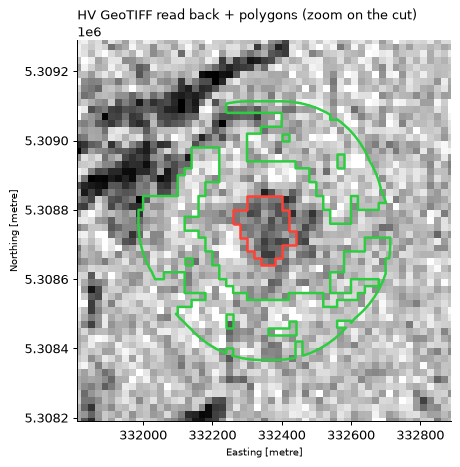

In [4]:
sites = gpd.read_file(kit["aoi"]["site_polygons"]).to_crs(grid.epsg)
with rasterio.open(paths["HV_gamma0_dB"]) as r:
    a = r.read(1); b = r.bounds
cut = sites[sites.role == "cut"].geometry.iloc[0]
cx0, cy0, cx1, cy1 = cut.buffer(150).bounds
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.imshow(a, cmap="gray", vmin=np.nanpercentile(a, 2), vmax=np.nanpercentile(a, 98), extent=[b.left, b.right, b.bottom, b.top])
sites.boundary.plot(ax=ax, color=["#ff4136" if r == "cut" else "#2ecc40" for r in sites.role], lw=2)
ax.set_xlim(cx0 - 300, cx1 + 300); ax.set_ylim(cy0 - 300, cy1 + 300)
ax.set_title("HV GeoTIFF read back + polygons (zoom on the cut)", loc="left", fontsize=10)
fig.savefig(OUT / "10_overlay.png", dpi=110, bbox_inches="tight"); plt.show()

## QGIS checklist
1. *Layer → Add Raster Layer* → the three `.tif` files in the output folder printed below.
2. *Properties → Information*: CRS must read the EPSG printed above, pixel size 20 m.
3. *Add Vector Layer* → `config/site.geojson` (on-the-fly reprojection): the red polygon must sit
   on the dark HV patch.
4. *Symbology*: single-band grey, min/max = 2–98 % cumulative cut — the same stretch as notebook 08.

In [5]:
print(OUT)

/media/dell/Transcend1/nisar_data/kit/outputs/10


In [6]:
checks = {
    "CRS preserved": val.CRS.eq("EPSG:" + str(grid.epsg)).all(),
    "values identical after write/read": val["values identical"].all(),
    "pixel size = grid spacing": all(abs(r[0] - abs(grid.dx)) < 1e-6 for r in val.pixel),
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 10 STATUS: PASS")

  [x] CRS preserved
  [x] values identical after write/read
  [x] pixel size = grid spacing
Module 10 STATUS: PASS
